
# MarketPulse AI
## Stock Markets Analytics Zoomcamp 2026 — Capstone Project

### Notebook 02: Exploratory Data Analysis and Feature Engineering

**Objective:** Explore the merged market dataset and develop
predictive features for stock return forecasting and trading
strategy evaluation.

### Data Sources
1. Yahoo Finance — Historical Stock Prices
2. FRED — Macroeconomic Indicators
3. Alternative.me — Crypto Fear & Greed Index

### Workflow
1. Load and validate the merged dataset
2. Exploratory Data Analysis (EDA)
3. Analyze stock returns and volatility
4. Engineer 20+ predictive features
5. Define 10-trading-day forward return targets
6. Validate feature quality and prevent data leakage
7. Save the feature-engineered dataset

### Modeling Objective
Predict 10-trading-day forward stock returns and evaluate
whether predictions can support a profitable trading strategy
after transaction costs.

### Important Considerations
- Use chronological training and validation splits.
- Avoid future information in predictive features.
- Treat SPY as the benchmark, not a trading candidate.
- Validate economic indicator publication timing and revisions
  before final backtesting.


In [1]:

# Cell 1 - Import Libraries and Load Dataset

from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Display settings
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 120)

# Project directory
project_root = Path.cwd()

if project_root.name == "notebooks":
    project_root = project_root.parent

data_dir = project_root / "data"

# Load merged dataset
data_file = data_dir / "marketpulse_merged.parquet"
df = pd.read_parquet(data_file)

# Ensure proper datetime format
df["date"] = pd.to_datetime(df["date"])

# Sort dataset
df = df.sort_values(
    ["ticker", "date"]
).reset_index(drop=True)

print("MarketPulse AI - Notebook 02")
print("Dataset loaded successfully!")

print("\nDataset shape:", df.shape)
print("Unique tickers:", df["ticker"].nunique())
print("Trading dates:", df["date"].nunique())

print("\nDate range:")
print(df["date"].min(), "to", df["date"].max())

print("\nMissing values:", df.isna().sum().sum())

display(df.head())


MarketPulse AI - Notebook 02
Dataset loaded successfully!

Dataset shape: (46221, 14)
Unique tickers: 21
Trading dates: 2201

Date range:
2018-02-02 00:00:00 to 2026-11-04 00:00:00

Missing values: 0


,date,ticker,open,high,low,close,volume,treasury_10y,treasury_2y,fed_funds_rate,cpi,unemployment_rate,fear_greed_index,value_classification
0,2018-02-02,AAPL,38.770315,38.957160,37.392335,37.485756,346375200,2.78,2.16,1.41,248.859,4.0,30,Fear
1,2018-02-05,AAPL,37.158784,38.275182,36.434758,36.549202,290954000,2.84,2.15,1.41,248.859,4.0,24,Extreme Fear
2,2018-02-06,AAPL,36.161500,38.237814,35.967648,38.076660,272975200,2.77,2.08,1.41,248.859,4.0,11,Extreme Fear
3,2018-02-07,AAPL,38.090672,38.163074,37.151779,37.261547,206434400,2.79,2.10,1.41,248.859,4.0,8,Extreme Fear
4,2018-02-08,AAPL,37.436711,37.602538,36.208207,36.236233,217562000,2.84,2.15,1.42,248.859,4.0,36,Fear


In [2]:

# Cell 2 - Dataset Overview and Descriptive Statistics

print("DATASET INFORMATION")
print("-" * 50)

df.info()

print("\nNUMERICAL SUMMARY")
print("-" * 50)

display(
    df.describe().round(2)
)

print("\nRECORDS PER TICKER")
print("-" * 50)

ticker_counts = (
    df.groupby("ticker")
    .size()
    .sort_values(ascending=False)
)

display(
    ticker_counts.to_frame("record_count")
)

print("\nSENTIMENT CLASSIFICATION DISTRIBUTION")
print("-" * 50)

sentiment_distribution = (
    df.drop_duplicates("date")["value_classification"]
    .value_counts()
)

display(
    sentiment_distribution.to_frame("trading_days")
)


DATASET INFORMATION
--------------------------------------------------
<class 'pandas.DataFrame'>
RangeIndex: 46221 entries, 0 to 46220
Data columns (total 14 columns):
 #   Column                Non-Null Count  Dtype         
---  ------                --------------  -----         
 0   date                  46221 non-null  datetime64[ns]
 1   ticker                46221 non-null  str           
 2   open                  46221 non-null  float64       
 3   high                  46221 non-null  float64       
 4   low                   46221 non-null  float64       
 5   close                 46221 non-null  float64       
 6   volume                46221 non-null  int64         
 7   treasury_10y          46221 non-null  float64       
 8   treasury_2y           46221 non-null  float64       
 9   fed_funds_rate        46221 non-null  float64       
 10  cpi                   46221 non-null  float64       
 11  unemployment_rate     46221 non-null  float64       
 12  fear_greed_ind

,date,open,high,low,close,volume,treasury_10y,treasury_2y,fed_funds_rate,cpi,unemployment_rate,fear_greed_index
count,46221,46221.00,46221.00,46221.00,46221.00,4.622100e+04,46221.00,46221.00,46221.00,46221.00,46221.00,46221.00
mean,2022-06-18 18:17:49.695593216,198.46,200.51,196.37,198.49,4.637480e+07,3.01,2.75,2.67,287.92,4.55,45.93
min,2018-02-02 00:00:00,3.13,3.21,3.08,3.14,4.601000e+05,0.52,0.09,0.05,248.86,3.40,5.00
25%,2020-04-13 00:00:00,59.07,59.60,58.37,59.11,5.745800e+06,1.76,1.53,0.77,258.08,3.70,27.00
50%,2022-06-16 00:00:00,143.22,144.69,141.79,143.24,1.801970e+07,3.08,2.94,2.40,291.30,4.00,45.00
75%,2024-08-26 00:00:00,272.61,275.48,269.83,272.90,4.333110e+07,4.22,4.18,4.33,313.57,4.30,65.00
max,2026-11-04 00:00:00,1142.82,1148.37,1111.95,1146.46,2.511528e+09,5.31,5.19,5.33,336.30,14.80,95.00
std,NaN,187.61,189.40,185.69,187.59,9.988929e+07,1.30,1.63,1.89,28.74,1.83,21.95



RECORDS PER TICKER
--------------------------------------------------


,record_count
ticker,
AAPL,2201
AMZN,2201
BAC,2201
CAT,2201
COST,2201
CVX,2201
GE,2201
GOOGL,2201
GS,2201



SENTIMENT CLASSIFICATION DISTRIBUTION
--------------------------------------------------


,trading_days
value_classification,
Fear,638
Greed,580
Extreme Fear,495
Neutral,287
Extreme Greed,201


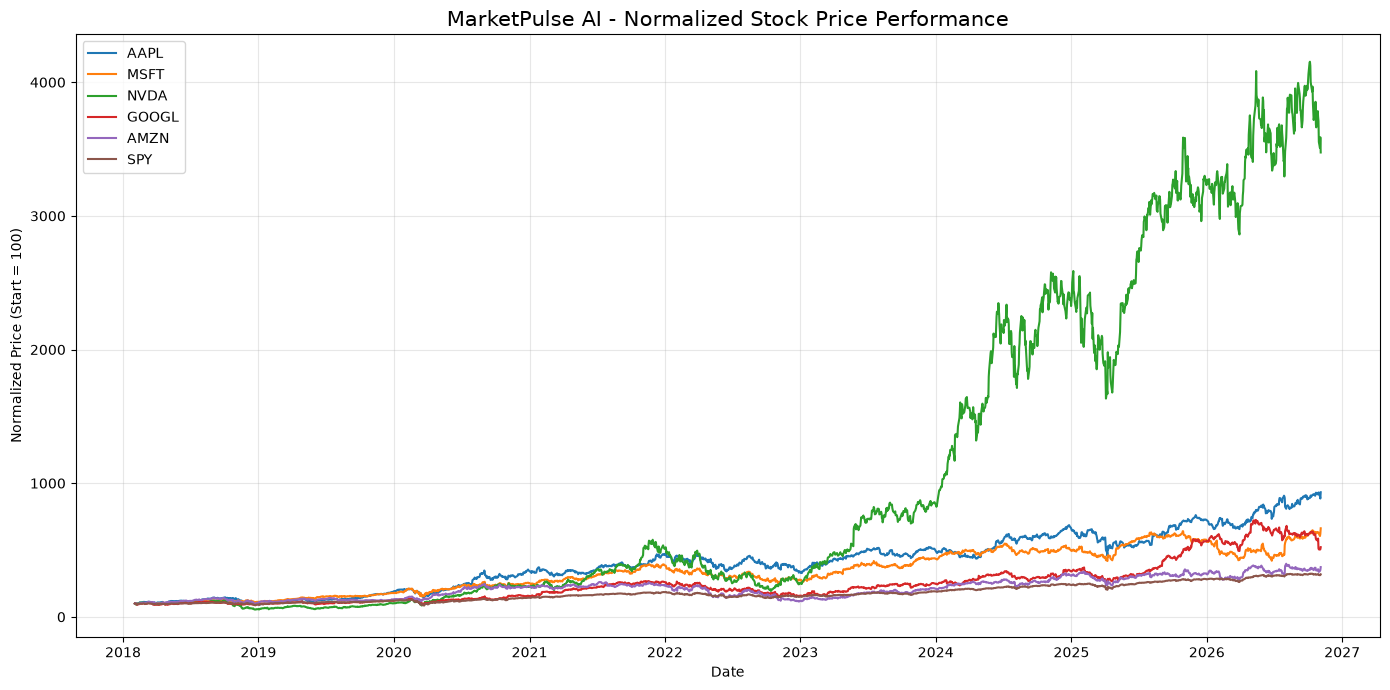

Normalized price dataset shape: (2201, 6)


ticker,AAPL,AMZN,GOOGL,MSFT,NVDA,SPY
date,,,,,,
2026-10-29,930.780226,340.976959,512.009949,632.020192,3709.477176,318.945656
2026-10-30,919.362559,336.165620,504.830028,622.208534,3552.875569,313.291055
2026-11-02,902.529505,343.550492,503.296621,604.576278,3508.082637,311.790351
2026-11-03,885.402964,350.627660,505.172792,621.111753,3588.466879,312.723111
2026-11-04,932.380850,372.082951,521.228339,662.611396,3474.574897,317.888534


In [3]:

# Cell 3 - Visualize Normalized Stock Prices

selected_tickers = [
    "AAPL", "MSFT", "NVDA",
    "GOOGL", "AMZN", "SPY"
]

# Filter selected stocks
price_data = df[
    df["ticker"].isin(selected_tickers)
].copy()

# Pivot into wide format
price_pivot = price_data.pivot(
    index="date",
    columns="ticker",
    values="close"
)

# Normalize each stock to 100 at the start
normalized_prices = (
    price_pivot / price_pivot.iloc[0] * 100
)

# Plot normalized prices
plt.figure(figsize=(14, 7))

for ticker in selected_tickers:
    plt.plot(
        normalized_prices.index,
        normalized_prices[ticker],
        label=ticker,
        linewidth=1.5
    )

plt.title(
    "MarketPulse AI - Normalized Stock Price Performance",
    fontsize=15
)
plt.xlabel("Date")
plt.ylabel("Normalized Price (Start = 100)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print("Normalized price dataset shape:",
      normalized_prices.shape)

display(normalized_prices.tail())


DAILY RETURNS AND VOLATILITY SUMMARY
--------------------------------------------------


,mean_daily_return_pct,annualized_return_approx,annualized_volatility
ticker,,,
NVDA,0.21,53.29,50.29
NFLX,0.08,19.65,42.48
META,0.09,22.64,41.78
GE,0.10,25.08,38.42
AMZN,0.08,21.01,34.57
CAT,0.09,22.67,33.04
UNH,0.05,13.40,31.90
BAC,0.05,12.78,31.48
GOOGL,0.09,23.85,31.38


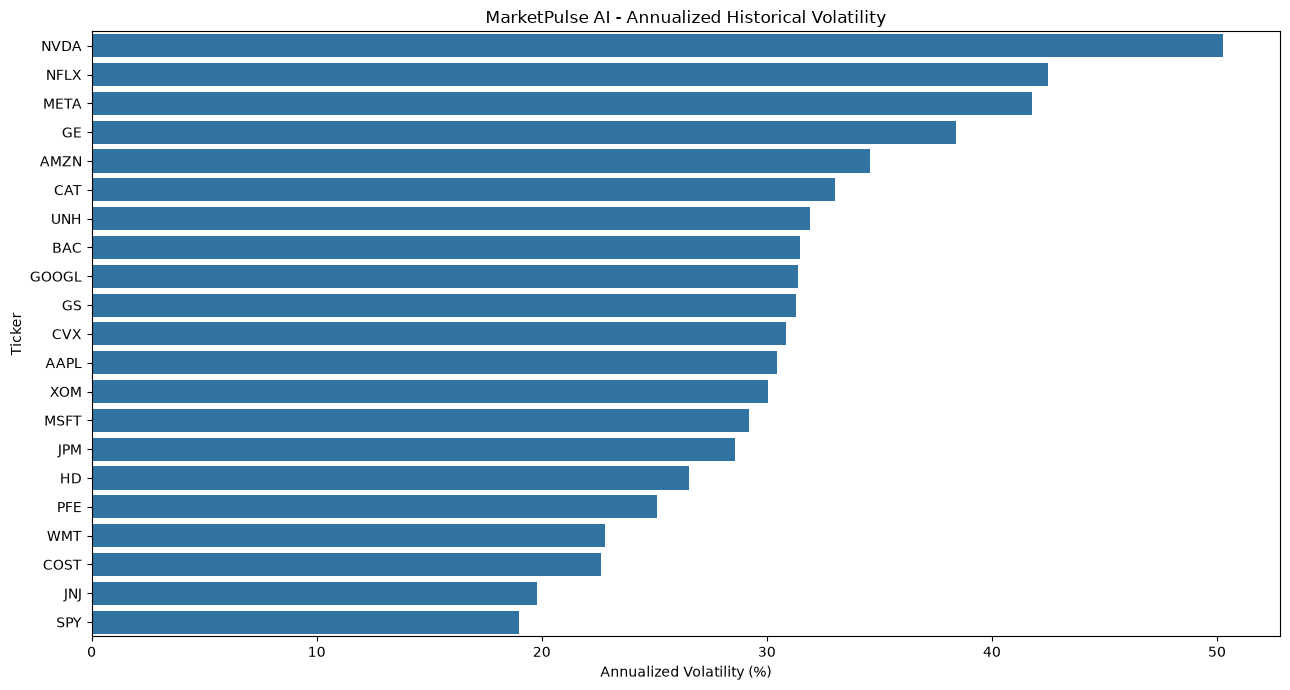


Missing daily returns: 21


In [4]:

# Cell 4 - Daily Returns and Volatility Analysis

# Create a working copy
eda_df = df.copy()

# Calculate daily returns separately for each ticker
eda_df["daily_return"] = (
    eda_df.groupby("ticker")["close"]
    .pct_change()
)

# Calculate annualized volatility
# Assumes approximately 252 trading days per year
volatility_summary = (
    eda_df.groupby("ticker")["daily_return"]
    .agg(["mean", "std"])
)

volatility_summary["annualized_return_approx"] = (
    volatility_summary["mean"] * 252 * 100
)

volatility_summary["annualized_volatility"] = (
    volatility_summary["std"] * np.sqrt(252) * 100
)

# Display percentage values
volatility_summary["mean_daily_return_pct"] = (
    volatility_summary["mean"] * 100
)

volatility_summary = volatility_summary[
    [
        "mean_daily_return_pct",
        "annualized_return_approx",
        "annualized_volatility"
    ]
].sort_values(
    "annualized_volatility",
    ascending=False
)

print("DAILY RETURNS AND VOLATILITY SUMMARY")
print("-" * 50)

display(volatility_summary.round(2))

# Visualize annualized volatility
plt.figure(figsize=(13, 7))

sns.barplot(
    data=volatility_summary.reset_index(),
    x="annualized_volatility",
    y="ticker"
)

plt.title(
    "MarketPulse AI - Annualized Historical Volatility"
)
plt.xlabel("Annualized Volatility (%)")
plt.ylabel("Ticker")
plt.tight_layout()
plt.show()

print("\nMissing daily returns:",
      eda_df["daily_return"].isna().sum())


Correlation matrix shape: (21, 21)


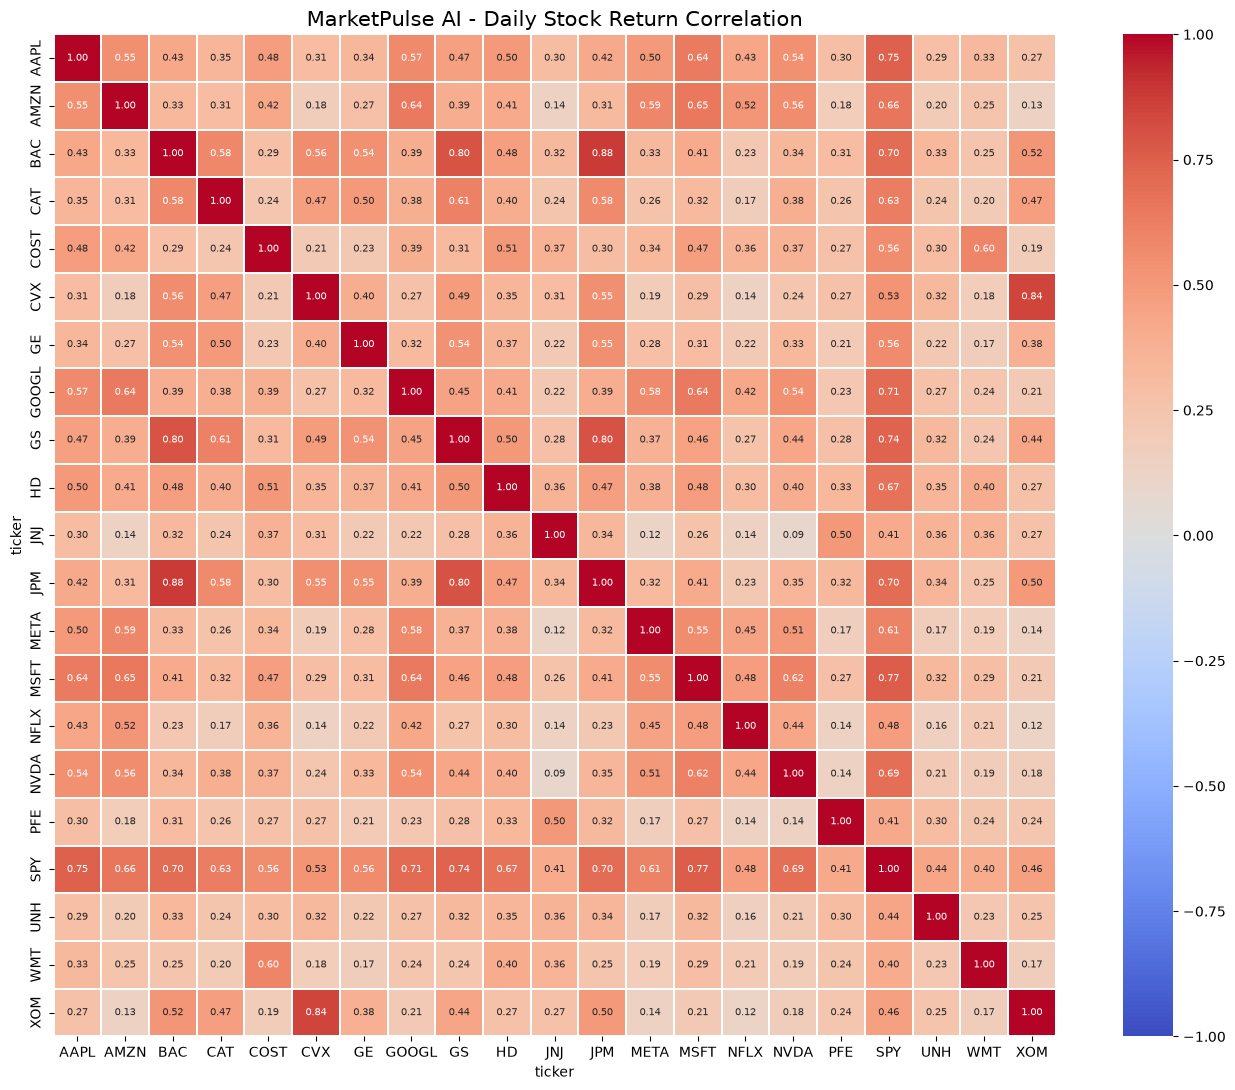


Total unique stock pairs: 190

Top 10 positively correlated stock pairs:


,,correlation
ticker,ticker,
BAC,JPM,0.878306
CVX,XOM,0.844828
GS,JPM,0.803389
BAC,GS,0.796102
AMZN,MSFT,0.653751
GOOGL,MSFT,0.642140
AMZN,GOOGL,0.641236
AAPL,MSFT,0.640617
MSFT,NVDA,0.615155



Top 10 least correlated stock pairs:


correlation
ticker ticker             
JNJ    NVDA       0.088668
NFLX   XOM        0.119710
JNJ    META       0.120399
AMZN   XOM        0.132876
       JNJ        0.137230
JNJ    NFLX       0.140201
META   XOM        0.140773
CVX    NFLX       0.140936
NFLX   PFE        0.141406
NVDA   PFE        0.142853

In [5]:

# Cell 5 - Stock Return Correlation Analysis

# Convert daily returns into wide format
returns_pivot = eda_df.pivot(
    index="date",
    columns="ticker",
    values="daily_return"
)

# Calculate correlation matrix
correlation_matrix = returns_pivot.corr()

print("Correlation matrix shape:",
      correlation_matrix.shape)

# Plot correlation heatmap
plt.figure(figsize=(14, 11))

sns.heatmap(
    correlation_matrix,
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    annot=True,
    fmt=".2f",
    square=True,
    linewidths=0.3,
    annot_kws={"size": 7}
)

plt.title(
    "MarketPulse AI - Daily Stock Return Correlation",
    fontsize=15
)

plt.tight_layout()
plt.show()

# Identify strongest and weakest stock correlations

# Exclude SPY benchmark
stock_corr = correlation_matrix.drop(
    index="SPY",
    columns="SPY"
)

# Extract unique stock pairs from upper triangle
upper_triangle = np.triu(
    np.ones(stock_corr.shape, dtype=bool),
    k=1
)

pairs = (
    stock_corr
    .where(upper_triangle)
    .stack()
    .dropna()
    .sort_values(ascending=False)
)

print("\nTotal unique stock pairs:", len(pairs))

print("\nTop 10 positively correlated stock pairs:")
display(
    pairs.head(10).to_frame("correlation")
)

print("\nTop 10 least correlated stock pairs:")
display(
    pairs.tail(10).sort_values().to_frame("correlation")
)


MAXIMUM DRAWDOWN SUMMARY
--------------------------------------------------


,max_drawdown_pct
ticker,
META,-76.74
NFLX,-75.95
NVDA,-66.34
GE,-62.27
UNH,-61.39
XOM,-61.01
PFE,-58.96
AMZN,-56.15
CVX,-55.77


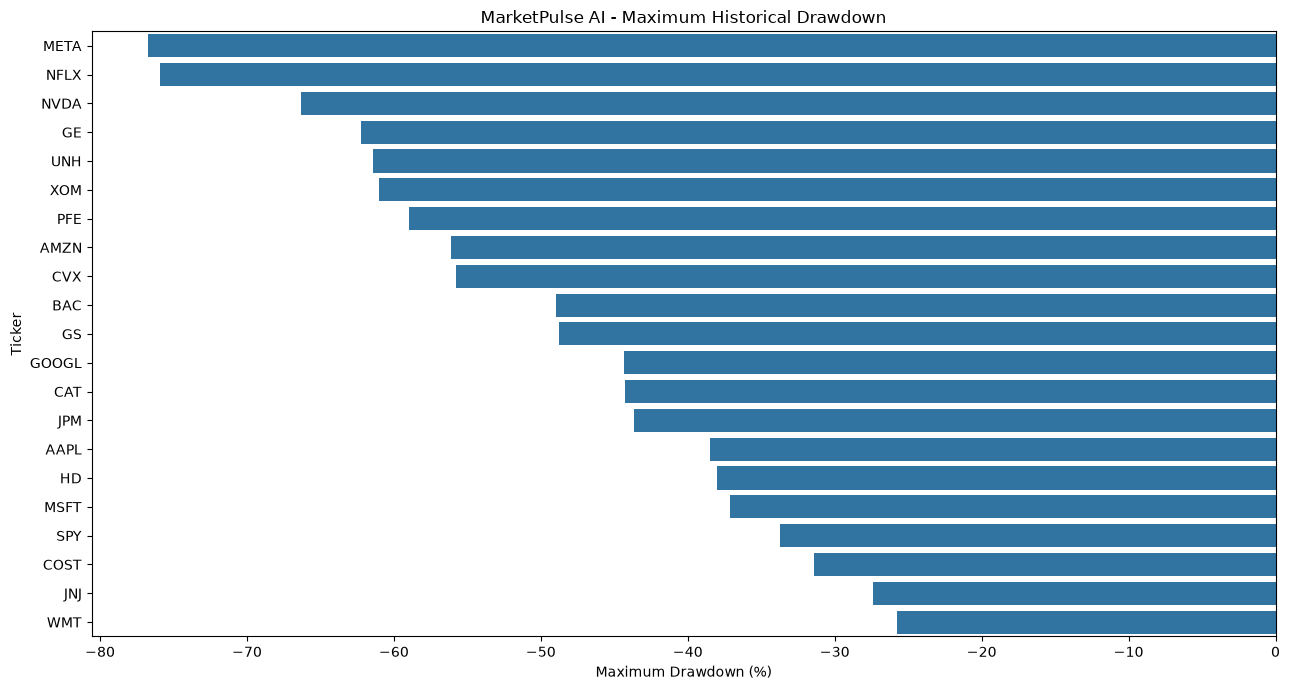

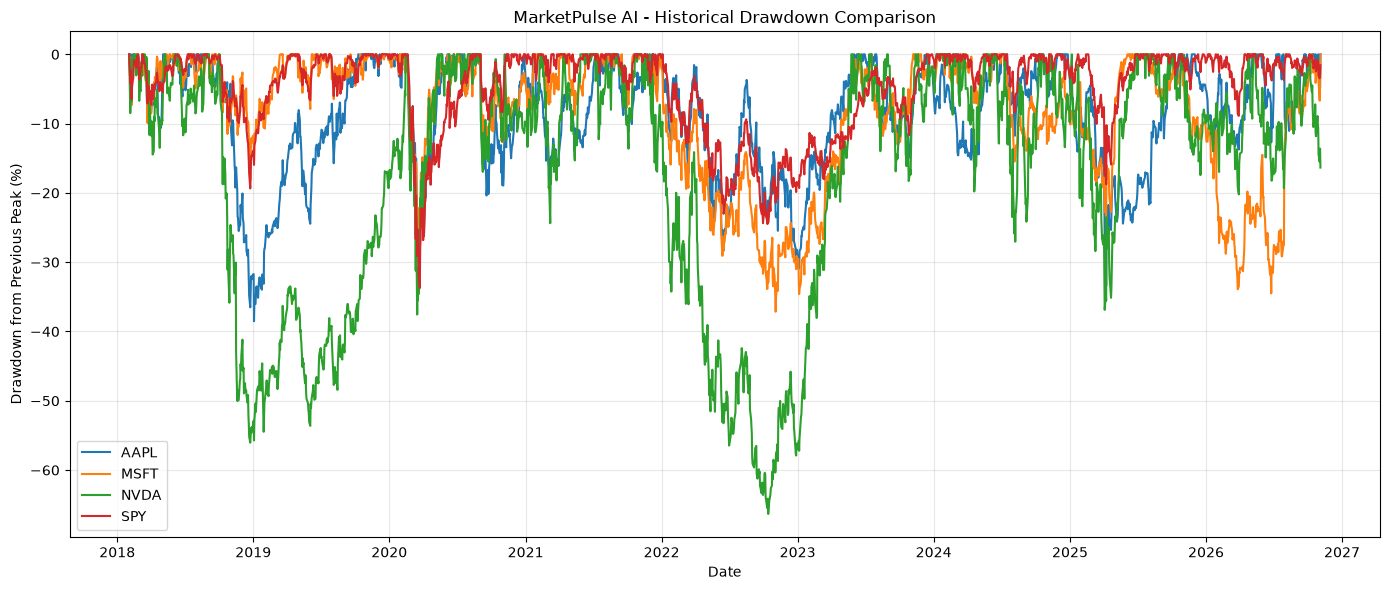

In [6]:

# Cell 6 - Maximum Drawdown Analysis

# Create working copy
drawdown_df = df[["date", "ticker", "close"]].copy()

# Calculate running peak for each ticker
drawdown_df["running_peak"] = (
    drawdown_df.groupby("ticker")["close"]
    .cummax()
)

# Calculate drawdown percentage
drawdown_df["drawdown_pct"] = (
    drawdown_df["close"] /
    drawdown_df["running_peak"] - 1
) * 100

# Calculate maximum drawdown for each ticker
max_drawdown = (
    drawdown_df.groupby("ticker")["drawdown_pct"]
    .min()
    .sort_values()
)

print("MAXIMUM DRAWDOWN SUMMARY")
print("-" * 50)

display(
    max_drawdown.to_frame("max_drawdown_pct").round(2)
)

# Plot maximum drawdowns
plt.figure(figsize=(13, 7))

sns.barplot(
    x=max_drawdown.values,
    y=max_drawdown.index
)

plt.title(
    "MarketPulse AI - Maximum Historical Drawdown"
)
plt.xlabel("Maximum Drawdown (%)")
plt.ylabel("Ticker")
plt.tight_layout()
plt.show()

# Compare selected stocks with SPY
selected_drawdowns = drawdown_df[
    drawdown_df["ticker"].isin(
        ["AAPL", "MSFT", "NVDA", "SPY"]
    )
]

plt.figure(figsize=(14, 6))

for ticker in ["AAPL", "MSFT", "NVDA", "SPY"]:
    subset = selected_drawdowns[
        selected_drawdowns["ticker"] == ticker
    ]

    plt.plot(
        subset["date"],
        subset["drawdown_pct"],
        label=ticker
    )

plt.title(
    "MarketPulse AI - Historical Drawdown Comparison"
)
plt.xlabel("Date")
plt.ylabel("Drawdown from Previous Peak (%)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


SPY RETURNS BY SENTIMENT CLASSIFICATION
--------------------------------------------------


,count,mean,median,std
value_classification,,,,
Extreme Fear,495,0.052,0.060,1.755
Fear,637,0.012,0.055,1.189
Neutral,287,0.037,0.038,0.888
Greed,580,0.110,0.111,0.803
Extreme Greed,201,0.118,0.157,0.792


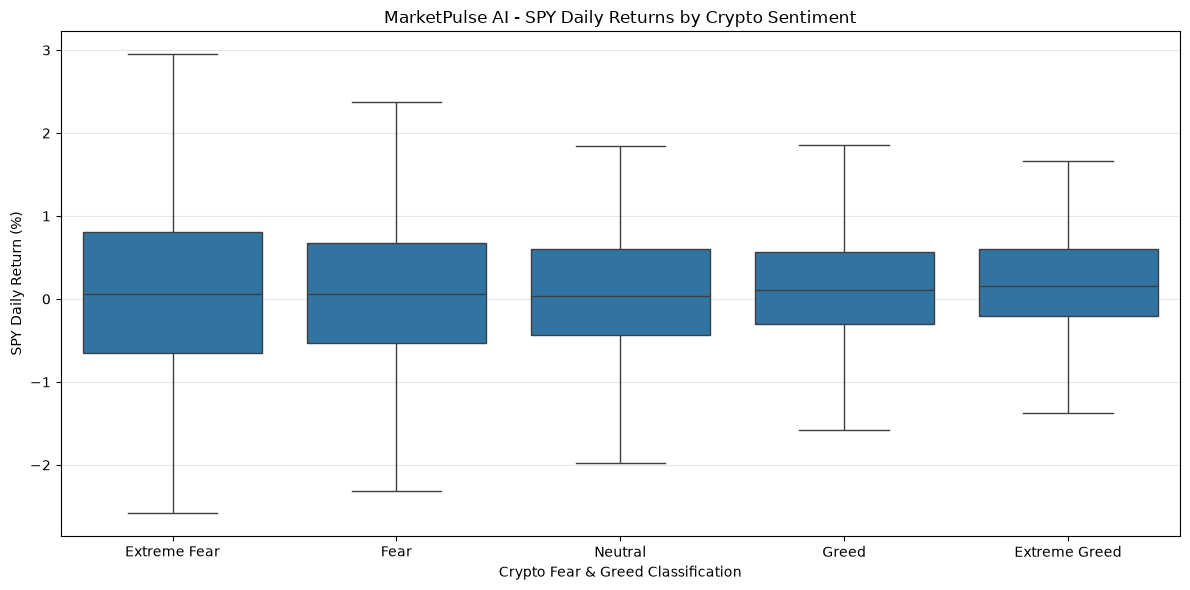


Correlation between Crypto Fear & Greed and SPY daily returns: 0.0261


In [7]:

# Cell 7 - Market Sentiment and SPY Returns

# Select SPY benchmark data
spy_df = eda_df[
    eda_df["ticker"] == "SPY"
].copy()

# Remove the first missing daily return
spy_df = spy_df.dropna(
    subset=["daily_return"]
)

# Convert returns to percentage
spy_df["daily_return_pct"] = (
    spy_df["daily_return"] * 100
)

# Define sentiment category order
sentiment_order = [
    "Extreme Fear",
    "Fear",
    "Neutral",
    "Greed",
    "Extreme Greed"
]

# Calculate summary statistics
sentiment_returns = (
    spy_df.groupby("value_classification")[
        "daily_return_pct"
    ]
    .agg(["count", "mean", "median", "std"])
    .reindex(sentiment_order)
)

print("SPY RETURNS BY SENTIMENT CLASSIFICATION")
print("-" * 50)

display(sentiment_returns.round(3))

# Plot return distributions
plt.figure(figsize=(12, 6))

sns.boxplot(
    data=spy_df,
    x="value_classification",
    y="daily_return_pct",
    order=sentiment_order,
    showfliers=False
)

plt.title(
    "MarketPulse AI - SPY Daily Returns by Crypto Sentiment"
)
plt.xlabel("Crypto Fear & Greed Classification")
plt.ylabel("SPY Daily Return (%)")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

# Calculate correlation
sentiment_corr = spy_df[
    ["fear_greed_index", "daily_return"]
].corr().iloc[0, 1]

print(
    "\nCorrelation between Crypto Fear & Greed "
    "and SPY daily returns:",
    round(sentiment_corr, 4)
)


MACROECONOMIC CORRELATION MATRIX
--------------------------------------------------


,treasury_10y,treasury_2y,fed_funds_rate,cpi,unemployment_rate,spy_return_pct
treasury_10y,1.000,0.958,0.887,0.826,-0.526,-0.009
treasury_2y,0.958,1.000,0.932,0.753,-0.550,-0.011
fed_funds_rate,0.887,0.932,1.000,0.737,-0.467,0.007
cpi,0.826,0.753,0.737,1.000,-0.275,0.004
unemployment_rate,-0.526,-0.550,-0.467,-0.275,1.000,0.031
spy_return_pct,-0.009,-0.011,0.007,0.004,0.031,1.000



CORRELATION WITH SPY DAILY RETURNS
--------------------------------------------------


,correlation
unemployment_rate,0.0307
fed_funds_rate,0.0072
cpi,0.0041
treasury_10y,-0.0088
treasury_2y,-0.0107


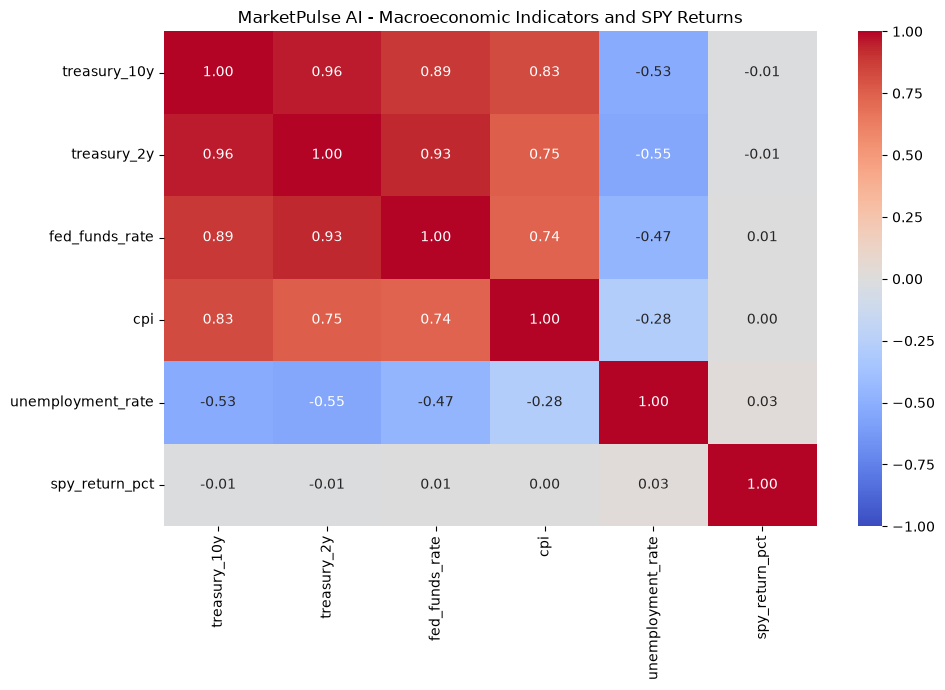

In [8]:

# Cell 8 - Macroeconomic Indicators and SPY Returns

macro_columns = [
    "treasury_10y",
    "treasury_2y",
    "fed_funds_rate",
    "cpi",
    "unemployment_rate"
]

# Use one row per trading day (SPY only)
spy_macro = eda_df[
    eda_df["ticker"] == "SPY"
].copy()

# Calculate daily SPY returns in percentage
spy_macro["spy_return_pct"] = (
    spy_macro["daily_return"] * 100
)

# Correlation matrix
macro_corr = spy_macro[
    macro_columns + ["spy_return_pct"]
].corr()

print("MACROECONOMIC CORRELATION MATRIX")
print("-" * 50)

display(macro_corr.round(3))

# Correlation with SPY daily returns
spy_macro_corr = (
    macro_corr["spy_return_pct"]
    .drop("spy_return_pct")
    .sort_values(ascending=False)
)

print("\nCORRELATION WITH SPY DAILY RETURNS")
print("-" * 50)

display(
    spy_macro_corr.to_frame("correlation").round(4)
)

# Plot heatmap
plt.figure(figsize=(10, 7))

sns.heatmap(
    macro_corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1
)

plt.title(
    "MarketPulse AI - Macroeconomic Indicators and SPY Returns"
)
plt.tight_layout()
plt.show()


In [9]:

# Cell 9 - Feature Engineering: Price Momentum

# Create feature engineering dataset
features_df = df.copy()

# Ensure correct ordering
features_df = (
    features_df
    .sort_values(["ticker", "date"])
    .reset_index(drop=True)
)

# Group data by ticker
grouped = features_df.groupby("ticker")["close"]

# Calculate historical price momentum
features_df["return_1d"] = grouped.pct_change(1)
features_df["return_5d"] = grouped.pct_change(5)
features_df["return_10d"] = grouped.pct_change(10)
features_df["return_20d"] = grouped.pct_change(20)

# Display new features
momentum_columns = [
    "ticker",
    "date",
    "close",
    "return_1d",
    "return_5d",
    "return_10d",
    "return_20d"
]

print("PRICE MOMENTUM FEATURES")
print("-" * 50)

display(
    features_df[momentum_columns].head(25)
)

print("\nMissing values in momentum features:")
print(
    features_df[
        ["return_1d", "return_5d",
         "return_10d", "return_20d"]
    ].isna().sum()
)

print("\nFeature engineering dataset shape:",
      features_df.shape)


PRICE MOMENTUM FEATURES
--------------------------------------------------


,ticker,date,close,return_1d,return_5d,return_10d,return_20d
0,AAPL,2018-02-02,37.485756,NaN,NaN,NaN,NaN
1,AAPL,2018-02-05,36.549202,-0.024984,NaN,NaN,NaN
2,AAPL,2018-02-06,38.076660,0.041792,NaN,NaN,NaN
3,AAPL,2018-02-07,37.261547,-0.021407,NaN,NaN,NaN
4,AAPL,2018-02-08,36.236233,-0.027517,NaN,NaN,NaN
5,AAPL,2018-02-09,36.679451,0.012231,-0.021510,NaN,NaN
6,AAPL,2018-02-12,38.156853,0.040279,0.043986,NaN,NaN
7,AAPL,2018-02-13,38.539101,0.010018,0.012145,NaN,NaN
8,AAPL,2018-02-14,39.249668,0.018438,0.053356,NaN,NaN
9,AAPL,2018-02-15,40.567608,0.033578,0.119532,NaN,NaN



Missing values in momentum features:
return_1d      21
return_5d     105
return_10d    210
return_20d    420
dtype: int64

Feature engineering dataset shape: (46221, 18)


In [10]:

# Cell 10 - Feature Engineering: Moving Averages

# Simple Moving Averages (SMA)
for window in [5, 10, 20, 50]:
    features_df[f"sma_{window}"] = (
        features_df.groupby("ticker")["close"]
        .transform(
            lambda x: x.rolling(
                window=window,
                min_periods=window
            ).mean()
        )
    )

# Exponential Moving Averages (EMA)
for span in [12, 26]:
    features_df[f"ema_{span}"] = (
        features_df.groupby("ticker")["close"]
        .transform(
            lambda x: x.ewm(
                span=span,
                adjust=False,
                min_periods=span
            ).mean()
        )
    )

# Display new features
ma_columns = [
    "ticker",
    "date",
    "close",
    "sma_5",
    "sma_10",
    "sma_20",
    "sma_50",
    "ema_12",
    "ema_26"
]

print("MOVING AVERAGE FEATURES")
print("-" * 50)

display(
    features_df[ma_columns].iloc[45:55]
)

print("\nMissing values in moving averages:")
print(
    features_df[
        ["sma_5", "sma_10", "sma_20",
         "sma_50", "ema_12", "ema_26"]
    ].isna().sum()
)

print("\nFeature engineering dataset shape:",
      features_df.shape)


MOVING AVERAGE FEATURES
--------------------------------------------------


,ticker,date,close,sma_5,sma_10,sma_20,sma_50,ema_12,ema_26
45,AAPL,2018-04-10,40.628574,40.152055,39.720086,40.302723,NaN,40.039542,40.150448
46,AAPL,2018-04-11,40.438618,40.190981,39.816235,40.214430,NaN,40.100938,40.171794
47,AAPL,2018-04-12,40.837288,40.253830,39.995869,40.164011,NaN,40.214223,40.221090
48,AAPL,2018-04-13,40.975647,40.551656,40.158854,40.118048,NaN,40.331365,40.276983
49,AAPL,2018-04-16,41.231262,40.822278,40.373195,40.092252,40.179927,40.469811,40.347670
50,AAPL,2018-04-17,41.798767,41.056316,40.604186,40.126725,40.266187,40.674266,40.455159
51,AAPL,2018-04-18,41.704975,41.309588,40.750285,40.157211,40.369303,40.832836,40.547738
52,AAPL,2018-04-19,40.523045,41.246739,40.750285,40.175151,40.418230,40.785176,40.545909
53,AAPL,2018-04-20,38.862717,40.824153,40.687905,40.138450,40.450254,40.489413,40.421228
54,AAPL,2018-04-23,38.750168,40.327934,40.575106,40.141967,40.500532,40.221837,40.297446



Missing values in moving averages:
sma_5       84
sma_10     189
sma_20     399
sma_50    1029
ema_12     231
ema_26     525
dtype: int64

Feature engineering dataset shape: (46221, 24)


In [11]:

# Cell 11 - Feature Engineering: Volatility Features

# Rolling annualized volatility from daily returns
for window in [5, 20]:
    features_df[f"volatility_{window}d"] = (
        features_df.groupby("ticker")["return_1d"]
        .transform(
            lambda x: x.rolling(
                window=window,
                min_periods=window
            ).std() * np.sqrt(252)
        )
    )

# Daily high-low range relative to closing price
features_df["daily_range_pct"] = (
    (features_df["high"] - features_df["low"]) /
    features_df["close"]
)

# Previous closing price for each ticker
previous_close = (
    features_df.groupby("ticker")["close"].shift(1)
)

# True Range components
true_range = pd.concat(
    [
        features_df["high"] - features_df["low"],
        (features_df["high"] - previous_close).abs(),
        (features_df["low"] - previous_close).abs()
    ],
    axis=1
).max(axis=1)

# Average True Range over 14 trading days
features_df["atr_14"] = (
    true_range.groupby(features_df["ticker"])
    .transform(
        lambda x: x.rolling(
            window=14,
            min_periods=14
        ).mean()
    )
)

# Display results
volatility_columns = [
    "ticker",
    "date",
    "close",
    "volatility_5d",
    "volatility_20d",
    "daily_range_pct",
    "atr_14"
]

print("VOLATILITY FEATURES")
print("-" * 50)

display(
    features_df[volatility_columns].iloc[20:30]
)

print("\nMissing values in volatility features:")
print(
    features_df[
        [
            "volatility_5d",
            "volatility_20d",
            "daily_range_pct",
            "atr_14"
        ]
    ].isna().sum()
)

print("\nFeature engineering dataset shape:",
      features_df.shape)


VOLATILITY FEATURES
--------------------------------------------------


,ticker,date,close,volatility_5d,volatility_20d,daily_range_pct,atr_14
20,AAPL,2018-03-05,41.465767,0.148728,0.316668,0.018211,0.862320
21,AAPL,2018-03-06,41.430599,0.148824,0.297093,0.012000,0.845904
22,AAPL,2018-03-07,41.045994,0.157520,0.270656,0.009027,0.808049
23,AAPL,2018-03-08,41.493919,0.123188,0.254403,0.011586,0.747245
24,AAPL,2018-03-09,42.206821,0.162927,0.225232,0.014502,0.747413
25,AAPL,2018-03-12,42.614864,0.166861,0.224739,0.011996,0.740210
26,AAPL,2018-03-13,42.204472,0.196934,0.196617,0.023671,0.759473
27,AAPL,2018-03-14,41.845673,0.193722,0.201436,0.015187,0.756625
28,AAPL,2018-03-15,41.894920,0.183670,0.194452,0.012147,0.740208
29,AAPL,2018-03-16,41.747173,0.125227,0.159354,0.008426,0.700176



Missing values in volatility features:
volatility_5d      105
volatility_20d     420
daily_range_pct      0
atr_14             273
dtype: int64

Feature engineering dataset shape: (46221, 28)


In [12]:

# Cell 12 - Feature Engineering: Technical Indicators

# 1. Relative Strength Index (RSI 14)
price_change = features_df.groupby("ticker")["close"].diff()

gain = price_change.clip(lower=0)
loss = -price_change.clip(upper=0)

avg_gain = gain.groupby(features_df["ticker"]).transform(
    lambda x: x.rolling(14, min_periods=14).mean()
)

avg_loss = loss.groupby(features_df["ticker"]).transform(
    lambda x: x.rolling(14, min_periods=14).mean()
)

rs = avg_gain / avg_loss.replace(0, np.nan)

features_df["rsi_14"] = 100 - (100 / (1 + rs))

# Handle periods with no losses or no price changes
features_df.loc[
    (avg_loss == 0) & (avg_gain > 0), "rsi_14"
] = 100

features_df.loc[
    (avg_loss == 0) & (avg_gain == 0), "rsi_14"
] = 50

# 2. MACD
features_df["macd"] = (
    features_df["ema_12"] - features_df["ema_26"]
)

features_df["macd_signal"] = (
    features_df.groupby("ticker")["macd"]
    .transform(
        lambda x: x.ewm(
            span=9,
            adjust=False,
            min_periods=9
        ).mean()
    )
)

features_df["macd_histogram"] = (
    features_df["macd"] -
    features_df["macd_signal"]
)

# 3. Bollinger Bands (20-day SMA +/- 2 standard deviations)
rolling_std_20 = (
    features_df.groupby("ticker")["close"]
    .transform(
        lambda x: x.rolling(
            window=20,
            min_periods=20
        ).std()
    )
)

features_df["bollinger_upper"] = (
    features_df["sma_20"] + 2 * rolling_std_20
)

features_df["bollinger_lower"] = (
    features_df["sma_20"] - 2 * rolling_std_20
)

# Display new features
technical_columns = [
    "ticker",
    "date",
    "close",
    "rsi_14",
    "macd",
    "macd_signal",
    "macd_histogram",
    "bollinger_upper",
    "bollinger_lower"
]

print("TECHNICAL INDICATOR FEATURES")
print("-" * 50)

display(
    features_df[technical_columns].iloc[30:40].round(4)
)

print("\nMissing values in technical indicators:")
print(
    features_df[
        [
            "rsi_14",
            "macd",
            "macd_signal",
            "macd_histogram",
            "bollinger_upper",
            "bollinger_lower"
        ]
    ].isna().sum()
)

print("\nFeature engineering dataset shape:",
      features_df.shape)


TECHNICAL INDICATOR FEATURES
--------------------------------------------------


C:\Users\roban\AppData\Local\Temp\ipykernel_30560\2071865938.py:87: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  features_df[technical_columns].iloc[30:40].round(4)


,ticker,date,close,rsi_14,macd,macd_signal,macd_histogram,bollinger_upper,bollinger_lower
30,AAPL,2018-03-19,41.1093,42.4745,0.7392,NaN,NaN,42.7576,40.1446
31,AAPL,2018-03-20,41.0952,42.9135,0.6472,NaN,NaN,42.6942,40.2875
32,AAPL,2018-03-21,40.1642,41.1905,0.4935,NaN,NaN,42.6855,40.3010
33,AAPL,2018-03-22,39.5967,33.5569,0.3223,0.6900,-0.3678,42.8443,40.0565
34,AAPL,2018-03-23,38.6798,26.8693,0.1112,0.5743,-0.4630,43.1911,39.4621
35,AAPL,2018-03-26,40.5160,44.1546,0.0911,0.4776,-0.3865,43.1261,39.3817
36,AAPL,2018-03-27,39.4771,40.7469,-0.0086,0.3804,-0.3890,43.1461,39.1260
37,AAPL,2018-03-28,39.0409,35.5123,-0.1214,0.2800,-0.4014,43.1908,38.8084
38,AAPL,2018-03-29,39.3458,32.2467,-0.1840,0.1872,-0.3713,43.2272,38.6026
39,AAPL,2018-04-02,39.0879,27.6986,-0.2516,0.0995,-0.3511,43.2449,38.3615



Missing values in technical indicators:
rsi_14             294
macd               525
macd_signal        693
macd_histogram     693
bollinger_upper    399
bollinger_lower    399
dtype: int64

Feature engineering dataset shape: (46221, 34)


In [13]:

# Cell 13 - Feature Engineering: Volume Features

# Daily percentage change in trading volume
features_df["volume_change_1d"] = (
    features_df.groupby("ticker")["volume"]
    .pct_change()
)

# 20-day average trading volume
features_df["volume_sma_20"] = (
    features_df.groupby("ticker")["volume"]
    .transform(
        lambda x: x.rolling(
            window=20,
            min_periods=20
        ).mean()
    )
)

# Relative trading volume
features_df["relative_volume_20"] = (
    features_df["volume"] /
    features_df["volume_sma_20"]
)

# Logarithmic volume transformation
features_df["log_volume"] = np.log1p(
    features_df["volume"]
)

# Display new features
volume_columns = [
    "ticker",
    "date",
    "volume",
    "volume_change_1d",
    "volume_sma_20",
    "relative_volume_20",
    "log_volume"
]

print("VOLUME FEATURES")
print("-" * 50)

display(
    features_df[volume_columns].iloc[20:30]
    .round({
        "volume_change_1d": 4,
        "volume_sma_20": 2,
        "relative_volume_20": 4,
        "log_volume": 4
    })
)

print("\nMissing values in volume features:")
print(
    features_df[
        [
            "volume_change_1d",
            "volume_sma_20",
            "relative_volume_20",
            "log_volume"
        ]
    ].isna().sum()
)

print("\nFeature engineering dataset shape:",
      features_df.shape)


VOLUME FEATURES
--------------------------------------------------


,ticker,date,volume,volume_change_1d,volume_sma_20,relative_volume_20,log_volume
20,AAPL,2018-03-05,113605600,-0.2614,181945420.0,0.6244,18.5482
21,AAPL,2018-03-06,95154000,-0.1624,172155420.0,0.5527,18.3710
22,AAPL,2018-03-07,126814000,0.3327,164847360.0,0.7693,18.6582
23,AAPL,2018-03-08,95096400,-0.2501,159280460.0,0.5970,18.3704
24,AAPL,2018-03-09,128740800,0.3538,154839400.0,0.8314,18.6733
25,AAPL,2018-03-12,128828400,0.0007,147146300.0,0.8755,18.6740
26,AAPL,2018-03-13,126774000,-0.0159,141321100.0,0.8971,18.6579
27,AAPL,2018-03-14,117473600,-0.0734,140684940.0,0.8350,18.5817
28,AAPL,2018-03-15,90975200,-0.2256,137104720.0,0.6635,18.3261
29,AAPL,2018-03-16,157618800,0.7325,134756220.0,1.1697,18.8757



Missing values in volume features:
volume_change_1d       21
volume_sma_20         399
relative_volume_20    399
log_volume              0
dtype: int64

Feature engineering dataset shape: (46221, 38)


In [14]:

# Cell 14 - Feature Engineering: Macroeconomic Features

# Create one macroeconomic observation per trading day
macro_daily = (
    features_df[
        [
            "date",
            "treasury_10y",
            "treasury_2y",
            "fed_funds_rate",
            "cpi"
        ]
    ]
    .drop_duplicates(subset="date")
    .sort_values("date")
    .reset_index(drop=True)
)

# Treasury yield curve spread (percentage points)
macro_daily["yield_spread"] = (
    macro_daily["treasury_10y"] -
    macro_daily["treasury_2y"]
)

# Five-trading-day changes in Treasury yields
macro_daily["treasury_10y_change_5d"] = (
    macro_daily["treasury_10y"].diff(5)
)

macro_daily["treasury_2y_change_5d"] = (
    macro_daily["treasury_2y"].diff(5)
)

# Twenty-trading-day change in federal funds rate
macro_daily["fed_funds_change_20d"] = (
    macro_daily["fed_funds_rate"].diff(20)
)

# Sixty-trading-day percentage change in CPI
macro_daily["cpi_change_60d"] = (
    macro_daily["cpi"].pct_change(60)
)

# Select new features for merging
macro_feature_columns = [
    "yield_spread",
    "treasury_10y_change_5d",
    "treasury_2y_change_5d",
    "fed_funds_change_20d",
    "cpi_change_60d"
]

# Merge macro features back to stock observations
features_df = features_df.merge(
    macro_daily[["date"] + macro_feature_columns],
    on="date",
    how="left",
    validate="many_to_one"
)

# Display results
print("MACROECONOMIC FEATURES")
print("-" * 50)

display(
    macro_daily[
        ["date"] + macro_feature_columns
    ].iloc[60:70].round({
        "yield_spread": 4,
        "treasury_10y_change_5d": 4,
        "treasury_2y_change_5d": 4,
        "fed_funds_change_20d": 4,
        "cpi_change_60d": 6
    })
)

print("\nMissing values in macroeconomic features:")
print(
    features_df[macro_feature_columns].isna().sum()
)

print("\nFeature engineering dataset shape:",
      features_df.shape)


MACROECONOMIC FEATURES
--------------------------------------------------


,date,yield_spread,treasury_10y_change_5d,treasury_2y_change_5d,fed_funds_change_20d,cpi_change_60d
60,2018-05-01,0.46,-0.03,0.00,0.18,0.005497
61,2018-05-02,0.47,-0.03,0.02,0.18,0.005497
62,2018-05-03,0.48,-0.06,0.00,0.18,0.005497
63,2018-05-04,0.45,-0.06,0.00,0.18,0.005497
64,2018-05-07,0.44,-0.01,0.02,0.00,0.005497
65,2018-05-08,0.46,0.00,0.00,0.01,0.005497
66,2018-05-09,0.46,0.00,0.01,0.01,0.005497
67,2018-05-10,0.46,0.03,0.05,0.01,0.005497
68,2018-05-11,0.43,0.03,0.05,0.01,0.005497
69,2018-05-14,0.43,0.02,0.03,0.01,0.005497



Missing values in macroeconomic features:
yield_spread                 0
treasury_10y_change_5d     105
treasury_2y_change_5d      105
fed_funds_change_20d       420
cpi_change_60d            1260
dtype: int64

Feature engineering dataset shape: (46221, 43)


In [15]:

# Cell 15 - Feature Engineering: Sentiment Features

# One sentiment observation per trading date
sentiment_daily = (
    features_df[
        ["date", "fear_greed_index"]
    ]
    .drop_duplicates(subset="date")
    .sort_values("date")
    .reset_index(drop=True)
)

# Change in sentiment since previous trading day
sentiment_daily["sentiment_change_1d"] = (
    sentiment_daily["fear_greed_index"].diff(1)
)

# Rolling sentiment averages
sentiment_daily["sentiment_sma_5"] = (
    sentiment_daily["fear_greed_index"]
    .rolling(window=5, min_periods=5)
    .mean()
)

sentiment_daily["sentiment_sma_20"] = (
    sentiment_daily["fear_greed_index"]
    .rolling(window=20, min_periods=20)
    .mean()
)

# Rolling sentiment volatility
sentiment_daily["sentiment_volatility_20"] = (
    sentiment_daily["fear_greed_index"]
    .rolling(window=20, min_periods=20)
    .std()
)

# New sentiment feature columns
sentiment_feature_columns = [
    "sentiment_change_1d",
    "sentiment_sma_5",
    "sentiment_sma_20",
    "sentiment_volatility_20"
]

# Merge sentiment features back to all tickers
features_df = features_df.merge(
    sentiment_daily[
        ["date"] + sentiment_feature_columns
    ],
    on="date",
    how="left",
    validate="many_to_one"
)

print("SENTIMENT FEATURES")
print("-" * 50)

display(
    sentiment_daily[
        ["date", "fear_greed_index"] +
        sentiment_feature_columns
    ].iloc[20:30].round({
        "sentiment_sma_5": 2,
        "sentiment_sma_20": 2,
        "sentiment_volatility_20": 2
    })
)

print("\nMissing values in sentiment features:")
print(
    features_df[
        sentiment_feature_columns
    ].isna().sum()
)

print("\nFeature engineering dataset shape:",
      features_df.shape)


SENTIMENT FEATURES
--------------------------------------------------


,date,fear_greed_index,sentiment_change_1d,sentiment_sma_5,sentiment_sma_20,sentiment_volatility_20
20,2018-03-05,44,6.0,40.8,40.95,17.33
21,2018-03-06,55,11.0,44.4,42.50,17.12
22,2018-03-07,59,4.0,47.4,44.90,15.78
23,2018-03-08,37,-22.0,46.6,46.35,13.36
24,2018-03-09,39,2.0,46.8,46.50,13.26
25,2018-03-12,40,1.0,46.0,47.00,12.78
26,2018-03-13,41,1.0,43.2,47.50,12.31
27,2018-03-14,41,0.0,39.6,47.45,12.34
28,2018-03-15,40,-1.0,40.2,47.70,12.12
29,2018-03-16,32,-8.0,38.8,46.55,12.48



Missing values in sentiment features:
sentiment_change_1d         21
sentiment_sma_5             84
sentiment_sma_20           399
sentiment_volatility_20    399
dtype: int64

Feature engineering dataset shape: (46221, 47)


In [16]:

# Cell 16 - Create 10-Trading-Day Forward Return Targets

# Ensure chronological order within each ticker
features_df = (
    features_df
    .sort_values(["ticker", "date"])
    .reset_index(drop=True)
)

# Closing price 10 trading days into the future
features_df["future_close_10d"] = (
    features_df.groupby("ticker")["close"]
    .shift(-10)
)

# Regression target: forward 10-day percentage return
features_df["target_return_10d"] = (
    features_df["future_close_10d"] /
    features_df["close"] - 1
)

# Classification target: positive or non-positive return
# Preserve missing targets at the end of each ticker
features_df["target_direction_10d"] = (
    features_df["target_return_10d"]
    .gt(0)
    .astype("Int64")
    .where(features_df["target_return_10d"].notna())
)

# Display sample targets
target_columns = [
    "ticker",
    "date",
    "close",
    "future_close_10d",
    "target_return_10d",
    "target_direction_10d"
]

print("10-DAY FORWARD RETURN TARGETS")
print("-" * 50)

display(
    features_df[target_columns]
    .iloc[45:55]
    .round({
        "close": 4,
        "future_close_10d": 4,
        "target_return_10d": 6
    })
)

print("\nMissing values in targets:")
print(
    features_df[
        ["target_return_10d", "target_direction_10d"]
    ].isna().sum()
)

print("\nTarget direction distribution:")
print(
    features_df["target_direction_10d"]
    .value_counts(dropna=False)
)

print("\nFeature engineering dataset shape:",
      features_df.shape)


10-DAY FORWARD RETURN TARGETS
--------------------------------------------------


,ticker,date,close,future_close_10d,target_return_10d,target_direction_10d
45,AAPL,2018-04-10,40.6286,38.2108,-0.059509,0
46,AAPL,2018-04-11,40.4386,38.3773,-0.050974,0
47,AAPL,2018-04-12,40.8373,38.5110,-0.056965,0
48,AAPL,2018-04-13,40.9756,38.0654,-0.071024,0
49,AAPL,2018-04-16,41.2313,38.7549,-0.060061,0
50,AAPL,2018-04-17,41.7988,39.6554,-0.051279,0
51,AAPL,2018-04-18,41.7050,41.4071,-0.007142,0
52,AAPL,2018-04-19,40.5230,41.4822,0.023669,1
53,AAPL,2018-04-20,38.8627,43.1097,0.109281,1
54,AAPL,2018-04-23,38.7502,43.4216,0.120552,1



Missing values in targets:
target_return_10d       210
target_direction_10d    210
dtype: int64

Target direction distribution:
target_direction_10d
1       26372
0       19639
<NA>      210
Name: count, dtype: Int64

Feature engineering dataset shape: (46221, 50)


In [17]:

# Cell 17 - Feature Quality Checks

# Explicitly identify the 33 engineered predictive features
feature_columns = [
    # Price momentum
    "return_1d", "return_5d",
    "return_10d", "return_20d",

    # Moving averages
    "sma_5", "sma_10", "sma_20", "sma_50",
    "ema_12", "ema_26",

    # Volatility
    "volatility_5d", "volatility_20d",
    "daily_range_pct", "atr_14",

    # Technical indicators
    "rsi_14", "macd", "macd_signal",
    "macd_histogram",
    "bollinger_upper", "bollinger_lower",

    # Volume
    "volume_change_1d", "volume_sma_20",
    "relative_volume_20", "log_volume",

    # Macroeconomic
    "yield_spread",
    "treasury_10y_change_5d",
    "treasury_2y_change_5d",
    "fed_funds_change_20d",
    "cpi_change_60d",

    # Sentiment
    "sentiment_change_1d",
    "sentiment_sma_5",
    "sentiment_sma_20",
    "sentiment_volatility_20"
]

target_columns = [
    "target_return_10d",
    "target_direction_10d"
]

print("FEATURE QUALITY CHECKS")
print("-" * 50)

print("Number of engineered features:",
      len(feature_columns))

print("\nDuplicate ticker-date records:",
      features_df.duplicated(
          subset=["ticker", "date"]
      ).sum())

# Count missing feature values
missing_features = (
    features_df[feature_columns]
    .isna()
    .sum()
    .sort_values(ascending=False)
)

print("\nMissing values by feature:")
display(missing_features.to_frame("missing_count"))

# Check for positive or negative infinity
infinite_count = np.isinf(
    features_df[feature_columns].to_numpy(dtype=float)
).sum()

print("\nInfinite feature values:", infinite_count)

# Check rows with all engineered features available
complete_feature_mask = (
    features_df[feature_columns]
    .notna()
    .all(axis=1)
)

print("\nRows with complete engineered features:",
      complete_feature_mask.sum())

print("First complete-feature date:",
      features_df.loc[
          complete_feature_mask, "date"
      ].min())

# Check rows with complete features and known targets
model_ready_mask = (
    complete_feature_mask &
    features_df[target_columns].notna().all(axis=1)
)

print("\nRows with complete features and targets:",
      model_ready_mask.sum())

print("\nDataset shape:", features_df.shape)


FEATURE QUALITY CHECKS
--------------------------------------------------
Number of engineered features: 33

Duplicate ticker-date records: 0

Missing values by feature:


,missing_count
cpi_change_60d,1260
sma_50,1029
macd_histogram,693
macd_signal,693
ema_26,525
macd,525
fed_funds_change_20d,420
volatility_20d,420
return_20d,420
bollinger_upper,399



Infinite feature values: 0

Rows with complete engineered features: 44961
First complete-feature date: 2018-05-01 00:00:00

Rows with complete features and targets: 44751

Dataset shape: (46221, 50)


FEATURE CORRELATIONS WITH 10-DAY FORWARD RETURNS
-------------------------------------------------------

Top 10 positive correlations:


,correlation
volatility_20d,0.0765
volatility_5d,0.0576
daily_range_pct,0.0482
volume_sma_20,0.0437
log_volume,0.0334
sentiment_sma_5,0.0325
yield_spread,0.0145
sentiment_sma_20,0.0141
sentiment_change_1d,0.0100
macd_histogram,0.0060



Top 10 negative correlations:


,correlation
cpi_change_60d,-0.0900
fed_funds_change_20d,-0.0751
macd_signal,-0.0424
macd,-0.0378
treasury_10y_change_5d,-0.0308
bollinger_lower,-0.0287
sma_5,-0.0284
sma_10,-0.0282
ema_12,-0.0281
sma_20,-0.0278


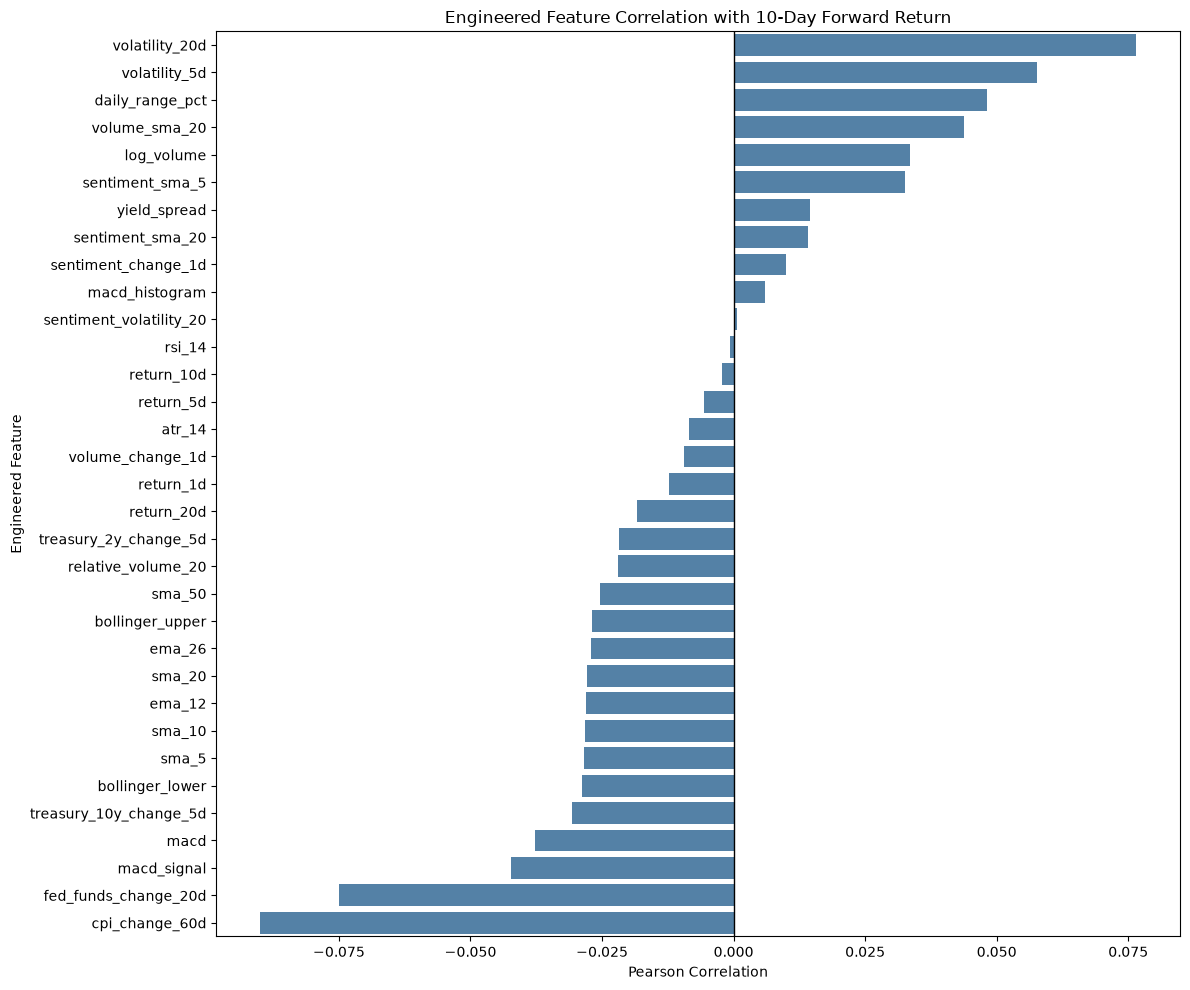


Saved correlation analysis: C:\Users\roban\marketpulse-ai\results\feature_target_correlations.csv
Number of features analyzed: 33


In [18]:

# Cell 18 - Feature-to-Target Correlation Analysis

# Use only complete observations with known targets.
# Exclude SPY because it is reserved for benchmarking.
correlation_df = features_df.loc[
    model_ready_mask & (features_df["ticker"] != "SPY"),
    feature_columns + ["target_return_10d"]
].copy()

# Pearson correlation between each feature and forward returns.
feature_target_corr = (
    correlation_df[feature_columns]
    .corrwith(correlation_df["target_return_10d"])
    .dropna()
    .sort_values(ascending=False)
)

print("FEATURE CORRELATIONS WITH 10-DAY FORWARD RETURNS")
print("-" * 55)

print("\nTop 10 positive correlations:")
display(feature_target_corr.head(10).to_frame("correlation").round(4))

print("\nTop 10 negative correlations:")
display(feature_target_corr.tail(10).sort_values().to_frame("correlation").round(4))

# Plot correlations for all engineered features.
plt.figure(figsize=(12, 10))

sns.barplot(
    x=feature_target_corr.values,
    y=feature_target_corr.index,
    color="steelblue"
)

plt.axvline(0, color="black", linewidth=1)
plt.title("Engineered Feature Correlation with 10-Day Forward Return")
plt.xlabel("Pearson Correlation")
plt.ylabel("Engineered Feature")
plt.tight_layout()
plt.show()

# Save the analysis for reproducibility.
correlation_path = project_root / "results" / "feature_target_correlations.csv"
correlation_path.parent.mkdir(parents=True, exist_ok=True)

feature_target_corr.rename("correlation").to_csv(
    correlation_path,
    header=True
)

print("\nSaved correlation analysis:", correlation_path)
print("Number of features analyzed:", len(feature_target_corr))


In [19]:

# Cell 19 - Prepare and Save Machine Learning Dataset

from pathlib import Path

data_dir = project_root / "data"
data_dir.mkdir(parents=True, exist_ok=True)

# Keep observations with complete features and targets
model_df = (
    features_df.loc[model_ready_mask]
    .copy()
    .sort_values(["date", "ticker"])
    .reset_index(drop=True)
)

# SPY is reserved for benchmark comparison
training_df = (
    model_df.loc[model_df["ticker"] != "SPY"]
    .copy()
    .reset_index(drop=True)
)

# Remove the future price helper from training data
# It must never be used as a predictive input
training_df = training_df.drop(
    columns=["future_close_10d"]
)

# Save complete engineered dataset for analysis/backtesting
full_path = data_dir / "marketpulse_features.parquet"
features_df.to_parquet(full_path, index=False)

# Save labeled, model-ready stock dataset
training_path = data_dir / "marketpulse_training.parquet"
training_df.to_parquet(training_path, index=False)

print("MACHINE LEARNING DATASET PREPARATION")
print("-" * 50)

print("Full engineered dataset:", features_df.shape)
print("Complete labeled dataset:", model_df.shape)
print("Stock training dataset:", training_df.shape)

print("\nTraining tickers:",
      training_df["ticker"].nunique())

print("SPY included in training:",
      "SPY" in training_df["ticker"].unique())

print("\nTraining date range:")
print("Start:", training_df["date"].min())
print("End:  ", training_df["date"].max())

print("\nMissing engineered features:",
      training_df[feature_columns].isna().sum().sum())

print("Missing targets:",
      training_df[target_columns].isna().sum().sum())

print("\nSaved files:")
print(full_path)
print(training_path)

# Verify saved files
verified_training = pd.read_parquet(training_path)

print("\nVerified saved training shape:",
      verified_training.shape)


MACHINE LEARNING DATASET PREPARATION
--------------------------------------------------
Full engineered dataset: (46221, 50)
Complete labeled dataset: (44751, 50)
Stock training dataset: (42620, 49)

Training tickers: 20
SPY included in training: False

Training date range:
Start: 2018-05-01 00:00:00
End:   2026-10-21 00:00:00

Missing engineered features: 0
Missing targets: 0

Saved files:
C:\Users\roban\marketpulse-ai\data\marketpulse_features.parquet
C:\Users\roban\marketpulse-ai\data\marketpulse_training.parquet

Verified saved training shape: (42620, 49)
